# Q1 In a reactor with excess A, the reaction A + B = C reaches equilibrium.Initial concentration are [A] = 2.0 [B] = 1.0 and [C] 0 mol/L of C is formed, Kc = x/((2-x)(1-x)), which rearranges to the quadratic equation Kc.x^2-(3Kc+1).x+2Kc=0.

In [25]:


import math

raw_kc = input("Enter Kc: ")
print("Raw input data type:", type(raw_kc).__name__)

try:
    kc = float(raw_kc)
except ValueError:
    print("Invalid input: Kc must be a number.")
else:
    print("Converted value data type:", type(kc).__name__)

    if not math.isfinite(kc):
        print("Invalid Kc: enter a finite number.")
    elif kc <= 0:
        print("Invalid Kc: it must be greater than 0.")
    else:
        # Kc*x^2 - (3*Kc + 1)*x + 2*Kc = 0
        a = kc
        b = -(3 * kc + 1)
        c = 2 * kc

        discriminant = b**2 - 4 * a * c
        sqrt_discriminant = math.sqrt(discriminant)

        root1 = (-b + sqrt_discriminant) / (2 * a)
        root2 = (-b - sqrt_discriminant) / (2 * a)

        print(f"a = {a}")
        print(f"b = {b}")
        print(f"c = {c}")
        print(f"Discriminant = {discriminant}")
        print(f"Root 1 = {root1}")
        print(f"Root 2 = {root2}")

        physical_root = None
        for root in (root1, root2):
            if 0 < root < 1:
                physical_root = root
                break

        if physical_root is None:
            print("No physically meaningful root was found.")
        else:
            conversion = physical_root / 1.0 * 100

            print(f"Equilibrium [C] = {physical_root:.3f} mol/L")
            print(f"Conversion of limiting reactant B = {conversion:.2f}%")

            if conversion > 70:
                print("Conversion classification: high")
            elif conversion > 40:
                print("Conversion classification: moderate")
            else:
                print("Conversion classification: low")

Raw input data type: str
Converted value data type: float
a = 0.5
b = -2.5
c = 1.0
Discriminant = 4.25
Root 1 = 4.561552812808831
Root 2 = 0.4384471871911697
Equilibrium [C] = 0.438 mol/L
Conversion of limiting reactant B = 43.84%
Conversion classification: moderate


# Q2 BATCH REACTOR SIMULATION AND BATCH TRACKING

# PartA. Hydrogen peroxide reactor decomposes in a batchmethod: C_new = C_old.delt. Take Co = 1.5 mol/L, k = 0.05 min^-1, delt = 2 min.

(a) using a for loop, simulate 20 mins and print a table of time (min), concentration(mol/L) and conversion(%).

In [5]:
Co = 1.5       # Initial concentration (mol/L)
k = 0.05       # Rate constant (min^-1)
dt = 2         # Time step (min)
total_time = 20

concentration = Co

print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")
print("-" * 56)
print(f"{0:10.1f} {concentration:24.4f} {0.0:18.2f}")

for time in range(dt, total_time + dt, dt):
    concentration = concentration - k * concentration * dt
    conversion = (Co - concentration) / Co * 100
    print(f"{time:10.1f} {concentration:24.4f} {conversion:18.2f}")

Time (min)    Concentration (mol/L)     Conversion (%)
--------------------------------------------------------
       0.0                   1.5000               0.00
       2.0                   1.3500              10.00
       4.0                   1.2150              19.00
       6.0                   1.0935              27.10
       8.0                   0.9842              34.39
      10.0                   0.8857              40.95
      12.0                   0.7972              46.86
      14.0                   0.7174              52.17
      16.0                   0.6457              56.95
      18.0                   0.5811              61.26
      20.0                   0.5230              65.13


(b) using math.exp(), calculate the exact value Coe^(-kt) at 20 mins and print the absolute error of the euler result.

In [6]:
import math

Co = 1.5       # Initial concentration (mol/L)
k = 0.05       # Rate constant (min^-1)
delta_t = 2    # Time step (min)
final_time = 20

steps = final_time // delta_t
concentration = Co

print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")

for step in range(steps + 1):
    time = step * delta_t
    conversion = (Co - concentration) / Co * 100

    print(f"{time:10.0f} {concentration:24.6f} {conversion:18.2f}")

    if step < steps:
        concentration = concentration - k * concentration * delta_t

exact_concentration = Co * math.exp(-k * final_time)
absolute_error = abs(exact_concentration - concentration)

print(f"\nEuler concentration at {final_time} min: {concentration:.6f} mol/L")
print(f"Exact concentration at {final_time} min: {exact_concentration:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

Time (min)    Concentration (mol/L)     Conversion (%)
         0                 1.500000               0.00
         2                 1.350000              10.00
         4                 1.215000              19.00
         6                 1.093500              27.10
         8                 0.984150              34.39
        10                 0.885735              40.95
        12                 0.797162              46.86
        14                 0.717445              52.17
        16                 0.645701              56.95
        18                 0.581131              61.26
        20                 0.523018              65.13

Euler concentration at 20 min: 0.523018 mol/L
Exact concentration at 20 min: 0.551819 mol/L
Absolute error: 0.028802 mol/L


(c) using a while loop, repeat the simulation until conversion reaches 50% or time reaches 100min. Print the time needed and the final concentration.

In [7]:
import math

Co = 1.5       # initial concentration, mol/L
k = 0.05       # rate constant, min^-1
delta_t = 2    # time step, min

# (a) Euler simulation for 20 minutes
time = 0
concentration = Co

print("(a) Euler simulation")
print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")

print(f"{time:10.0f} {concentration:24.4f} {0.0:18.2f}")

for _ in range(10):  # 10 steps of 2 minutes = 20 minutes
    concentration = concentration - k * concentration * delta_t
    time += delta_t
    conversion = (Co - concentration) / Co * 100
    print(f"{time:10.0f} {concentration:24.4f} {conversion:18.2f}")

euler_concentration = concentration

# (b) Exact concentration and absolute error at 20 minutes
exact_concentration = Co * math.exp(-k * 20)
absolute_error = abs(euler_concentration - exact_concentration)

print("\n(b) At 20 minutes")
print(f"Exact concentration: {exact_concentration:.6f} mol/L")
print(f"Absolute error:      {absolute_error:.6f} mol/L")

# (c) Continue with Euler steps until conversion reaches 50% or time reaches 100 min
time = 0
concentration = Co
conversion = 0

while conversion < 50 and time < 100:
    concentration = concentration - k * concentration * delta_t
    time += delta_t
    conversion = (Co - concentration) / Co * 100

print("\n(c) 50% conversion target")
print(f"Time needed: {time} min")
print(f"Final concentration: {concentration:.4f} mol/L")
print(f"Final conversion: {conversion:.2f}%")

(a) Euler simulation
Time (min)    Concentration (mol/L)     Conversion (%)
         0                   1.5000               0.00
         2                   1.3500              10.00
         4                   1.2150              19.00
         6                   1.0935              27.10
         8                   0.9842              34.39
        10                   0.8857              40.95
        12                   0.7972              46.86
        14                   0.7174              52.17
        16                   0.6457              56.95
        18                   0.5811              61.26
        20                   0.5230              65.13

(b) At 20 minutes
Exact concentration: 0.551819 mol/L
Absolute error:      0.028802 mol/L

(c) 50% conversion target
Time needed: 14 min
Final concentration: 0.7174 mol/L
Final conversion: 52.17%


# PartB. Reactor tags such as REACTOR-07/B-2026 are stored as text. Write a program that reads a tag, loops through each character, and prints the number of digits and th sum of the digits. Show a message for an empty tag and for a tag with no digits. Test with REACTOR-07/B-2026, an empty tag and ABCDEF

In [28]:
tag = input("Enter a reactor tag: ")

digit_count = 0
digit_sum = 0

for character in tag:
    if character.isdigit():
        digit_count += 1
        digit_sum += int(character)

if tag == "":
    print("The tag is empty.")
elif digit_count == 0:
    print("The tag contains no digits.")

print(f"Number of digits: {digit_count}")
print(f"Sum of digits: {digit_sum}")

The tag contains no digits.
Number of digits: 0
Sum of digits: 0


# Q3 CATALYST-PAIR SCREENING AND SAMPLING SCHEDULE

PartA. A laboratory has n candidate catalysts and wasnt to test r of them together (order does not matter). Write a recursive function factorial(n) (remember the base case for 0!) and a function combination(n,r) = n!/(r!(n-r)!) that uses it. Reject invalid input (negative values, r>n). Print the number of possible catalyts sets for n = 7, r = 2 and show the message for n = 4, r = 6

In [9]:
def factorial(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative numbers.")
    if n == 0:  # Base case: 0! = 1
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative.")
    if r > n:
        raise ValueError("Invalid input: r cannot be greater than n.")

    return factorial(n) // (factorial(r) * factorial(n - r))


# Valid example
print(f"Possible catalyst sets for n=7, r=2: {combination(7, 2)}")

# Invalid example
try:
    print(combination(4, 6))
except ValueError as error:
    print(error)

Possible catalyst sets for n=7, r=2: 21
Invalid input: r cannot be greater than n.


PartB. During a distillation run, samples are taken at times = Fibonacci number x 5 mins. Write an iterative function fib_iter(n) that return a list of the first n fibonacci numbers, and a recursive fucntion fib_rec(k) that return the k-th Fibonacci number (Fo = 0, F1 = 1) for n=9, check that both function agree and print a table: sample No., fibonacci tag, sampling tag(min) 

In [10]:
def fib_iter(n):
    """Return the first n Fibonacci numbers, starting with F0 = 0."""
    if n < 0:
        raise ValueError("n must be non-negative.")

    numbers = []
    a, b = 0, 1

    for _ in range(n):
        numbers.append(a)
        a, b = b, a + b

    return numbers


def fib_rec(k):
    """Return the k-th Fibonacci number, with F0 = 0 and F1 = 1."""
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k < 2:
        return k
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 9
fibonacci_numbers = fib_iter(n)

# Check the iterative list against the recursive function.
if all(value == fib_rec(index) for index, value in enumerate(fibonacci_numbers)):
    print("Check passed: both functions agree.")
else:
    print("Check failed: the functions do not agree.")

print(f"\n{'Sample No.':<12}{'Fibonacci tag':<16}{'Sampling time (min)'}")
for sample_no, fibonacci_tag in enumerate(fibonacci_numbers, start=1):
    sampling_time = fibonacci_tag * 5
    print(f"{sample_no:<12}{fibonacci_tag:<16}{sampling_time}")

Check passed: both functions agree.

Sample No.  Fibonacci tag   Sampling time (min)
1           0               0
2           1               5
3           1               5
4           2               10
5           3               15
6           5               25
7           8               40
8           13              65
9           21              105


# Q4.KINETICS AND GAS DATA: PANDAS AND MATPLOTLIB

In [11]:
pip install pandas


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
import pandas as pd

data = {
    'Time_min': [0, 10, 20, 30, 40, 50],
    'Run1_mol_L(low loading)': [1.20, 0.98, 0.80, 0.66, 0.54, 0.44],
    'Run2_mol_L(high loading)': [1.20, 0.80, 0.54, 0.36, 0.24, 0.16]
}

df = pd.DataFrame(data)
df

,Time_min,Run1_mol_L(low loading),Run2_mol_L(high loading)
0,0,1.20,1.20
1,10,0.98,0.80
2,20,0.80,0.54
3,30,0.66,0.36
4,40,0.54,0.24
5,50,0.44,0.16


(a) Create a dateframe from table. Save it as Kinetics.csv (without index column) and as Kinetics.json. Read the CSV back and print its shape and date types

In [13]:
# Save the DataFrame
df.to_csv("Kinetics.csv", index=False)
df.to_json("Kinetics.json", orient="records", indent=4)

# Read the CSV back and show its shape and data types
df_from_csv = pd.read_csv("Kinetics.csv")

print("Shape:", df_from_csv.shape)
print("Data types:")
print(df_from_csv.dtypes)

Shape: (6, 3)
Data types:
Time_min                      int64
Run1_mol_L(low loading)     float64
Run2_mol_L(high loading)    float64
dtype: object


(b) Print the mean and standard deviation of Run1 and Run2, and sate which run shows more variation.

In [14]:
run1_mean = df["Run1_mol_L(low loading)"].mean()
run1_std = df["Run1_mol_L(low loading)"].std()

run2_mean = df["Run2_mol_L(high loading)"].mean()
run2_std = df["Run2_mol_L(high loading)"].std()

print(f"Run1 mean: {run1_mean:.3f} mol/L")
print(f"Run1 standard deviation: {run1_std:.3f} mol/L")
print(f"Run2 mean: {run2_mean:.3f} mol/L")
print(f"Run2 standard deviation: {run2_std:.3f} mol/L")

if run1_std > run2_std:
    print("Run1 shows more variation.")
elif run2_std > run1_std:
    print("Run2 shows more variation.")
else:
    print("Both runs show the same variation.")

Run1 mean: 0.770 mol/L
Run1 standard deviation: 0.284 mol/L
Run2 mean: 0.550 mol/L
Run2 standard deviation: 0.392 mol/L
Run2 shows more variation.


(c) Plot both runs on one graph (time on x-axis) with title< axis labels with units, legend and grid.

In [17]:
pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 32.7 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 34.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 33.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 37.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]]  WARNING: The scripts fonttools, pyftmerge, pyftsubset and ttx are installed in '/usr/local/python/3.12.1/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


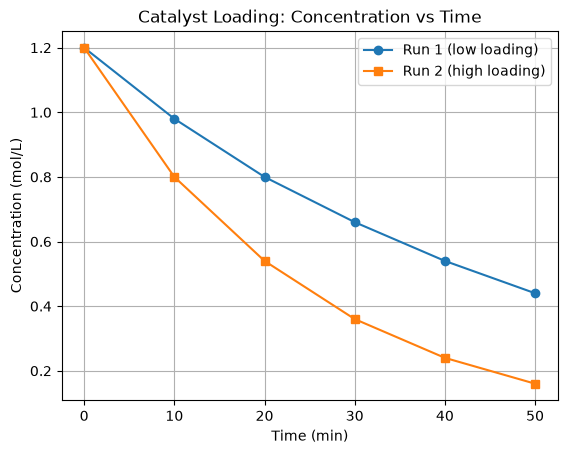

In [18]:
import matplotlib.pyplot as plt

plt.plot(df["Time_min"], df["Run1_mol_L(low loading)"], marker="o", label="Run 1 (low loading)")
plt.plot(df["Time_min"], df["Run2_mol_L(high loading)"], marker="s", label="Run 2 (high loading)")

plt.title("Catalyst Loading: Concentration vs Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.show()

(d) Carbon dioxide is compressed slowly in a piston-cylinder at constant temperature:

In [19]:
import pandas as pd

data = {
    'Volume_L': [1, 2, 3, 4, 5],
    'Pressure_bar': [3.02, 1.49, 1.01, 0.76, 0.59]
}

df = pd.DataFrame(data)
df

,Volume_L,Pressure_bar
0,1,3.02
1,2,1.49
2,3,1.01
3,4,0.76
4,5,0.59


Plot pressurevs. volume as a scatter plot. Calculate k as the mean of PxV and draw the reference curve P=k/V on the same graph. Add title, labels with units and legends.

Mean k = 3.004 bar·L


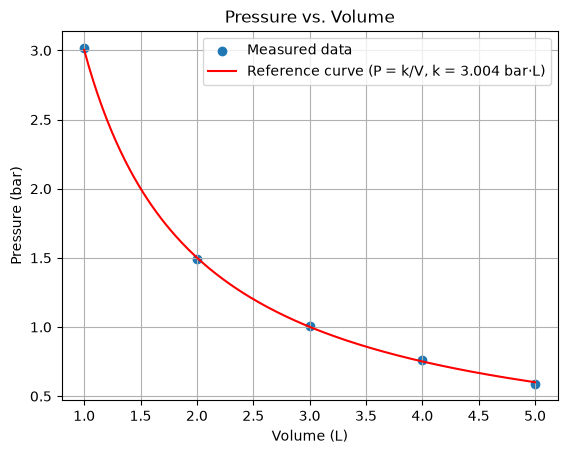

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate k as the mean of P × V
k = (df["Pressure_bar"] * df["Volume_L"]).mean()
print(f"Mean k = {k:.3f} bar·L")

# Smooth reference curve over the measured volume range
volume_curve = np.linspace(df["Volume_L"].min(), df["Volume_L"].max(), 200)
pressure_curve = k / volume_curve

plt.scatter(df["Volume_L"], df["Pressure_bar"], label="Measured data")
plt.plot(volume_curve, pressure_curve, color="red", label=f"Reference curve (P = k/V, k = {k:.3f} bar·L)")

plt.title("Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.show()